![Banner](../images/09_07_banner_rs_texture.png)


# Texture Analysis of Landsat Imagery: Deep-Learning-Based Methods

Hand-crafted texture measures are designed by people: a co-occurrence matrix, a Gabor filter, a binary pattern.


## Overview

Convolutional neural networks (CNNs) **learn** their filters from millions of images, and their early layers turn out to be excellent general-purpose texture descriptors. This notebook explains how CNNs represent texture, extracts feature maps from an ImageNet-pretrained ResNet-18 for a Landsat 9 scene over Las Vegas with `geolattice.rsense.texture.deep_texture_features`, compares layers and band choices, uses the features for tile-level search and clustering, and relates them to the hand-crafted measures of the previous notebooks.


### Image texture in brief

Spectral values tell us *what* a pixel is made of; **texture** tells us *how pixel values are arranged*
around it. Texture is the spatial variation of gray levels inside a neighbourhood and describes
properties such as smoothness, coarseness, regularity, directionality and contrast. Haralick,
Shanmugam and Dinstein (1973) noted that tone and texture are always present together in an image, but
one may dominate the other depending on the scene.

At Landsat's 30 m resolution many land-cover classes overlap spectrally: urban fabric, bare soil and
rock are all bright and dry in an arid scene; crop types or forest stands can share the same NDVI;
rough terrain mixes lit slopes and shadow within a few pixels. Texture separates such classes because
it responds to *pattern*, not only to *brightness*, and texture layers are routinely stacked with bands
and indices as predictors in land-cover classification, urban mapping, forest-structure modelling and
soil mapping.

Methods are usually grouped into six families. This series covers them in five notebooks:

| Notebook | Family | Methods |
|---|---|---|
| 09_07_01 | [Statistical and structural texture](09_07_01_texture_analysis_of_landsat_imagery_statistical_and_structural_methods.ipynb) | First-order statistics, GLCM, GLRLM, edge density, lacunarity |
| 09_07_02 | [Transform-based (spectral) texture](09_07_02_texture_analysis_of_landsat_imagery_transform_based_spectral_methods.ipynb) | Fourier power spectrum, Gabor filter bank, Haar wavelets |
| 09_07_03 | [Local pattern-based texture](09_07_03_texture_analysis_of_landsat_imagery_local_pattern_based_methods_lbp.ipynb) | Local Binary Patterns (LBP) |
| 09_07_04 | [Model-based texture](09_07_04_texture_analysis_of_landsat_imagery_model_based_methods.ipynb) | Markov Random Field energy, fractal dimension, autoregressive model |
| 09_07_05 | **Deep-learning-based texture** (this notebook) | Pretrained CNN feature maps |

All methods come from `geolattice.rsense.texture`. Every function accepts a 2-D `xr.DataArray` (or NumPy
array) and returns a georeferenced result with the same shape as the input; inputs with leading
dimensions (band, time, polarization) are processed slice by slice, and multi-feature methods return an
`xr.Dataset` with one variable per feature.


### Theory: how a CNN describes texture

**Convolution layers.** A CNN applies a stack of learned filter banks. Layer $\ell$ convolves its input
$x^{(\ell-1)}$ (with $C_{\ell-1}$ channels) with $C_\ell$ kernels $w^{(\ell)}_k$, adds a bias and applies a
nonlinearity (ReLU, $\max(0, z)$):

$$x^{(\ell)}_k = \operatorname{ReLU}\!\Big(\sum_{c=1}^{C_{\ell-1}} w^{(\ell)}_{k,c} * x^{(\ell-1)}_c + b^{(\ell)}_k\Big).$$

Strided convolutions and pooling halve the resolution at each stage, so deeper layers see larger areas
(a larger **receptive field**) with more channels. Each output channel is a **feature map**: the response
of one learned filter at every location, exactly like one Gabor energy map, but with filters learned
from data instead of designed by hand.

**What the layers learn.** Visualizations of trained networks (Zeiler and Fergus 2014) show a clear
hierarchy:

| Depth | Learned filters respond to | Hand-crafted analogue |
|---|---|---|
| First convolution | Oriented edges, colour blobs, colour-opponent edges | Gabor filters, local gradients |
| Early stages | Corners, junctions, repeated stripes, simple textures | LBP, GLCM, Gabor energy |
| Middle stages | Texture motifs, object parts | Texton histograms |
| Late stages | Object classes (dog, car, ...) | none |

For texture, the **early and middle** stages are the most useful: late layers are specific to the
ImageNet object categories, while early layers transfer to almost any image domain.

**Texture as feature statistics.** Gatys, Ecker and Bethge (2015) showed that the correlations between
feature maps, the **Gram matrix** $G_{ij} = \sum_{x} F_i(x)F_j(x)$, capture a texture so completely that
new images with the same texture can be synthesized from it. Cimpoi, Maji and Vedaldi (2015) pooled CNN
feature maps into orderless descriptors ("deep filter banks") that outperformed hand-crafted texture
features on material and scene recognition. The mean of each feature map over a region (`reduce="mean"`
below) is the simplest such pooled descriptor.

**Transfer to remote sensing.** Penatti, Nogueira and dos Santos (2015) and Hu et al. (2015) showed that
ImageNet-pretrained CNNs, used as fixed feature extractors without retraining, beat hand-crafted
descriptors for aerial and satellite scene classification. Two practical issues arise with
multispectral imagery:

- **Three input channels.** ImageNet networks expect RGB. We pass three bands (a colour-infrared
  composite NIR-red-green, true colour, or one band repeated three times).
- **Resolution and object size.** ImageNet objects span hundreds of pixels; at 30 m, a city block is
  only 3 to 5 pixels. Early stages, whose receptive fields are small, match Landsat best.


### ResNet-18 feature stages

`deep_texture_features(img, model_name, layer, reduce)` uses `timm` to build the backbone with
`features_only=True` and returns the channels of stage `layer`:

| `layer` | Stage | Channels | Stride | Receptive field | Ground footprint at 30 m |
|---|---|---|---|---|---|
| 0 | stem (7 × 7 conv) | 64 | 2 | 7 px | 210 m |
| 1 | layer1 | 64 | 4 | 43 px | 1.3 km |
| 2 | layer2 | 128 | 8 | 99 px | 3.0 km |
| 3 | layer3 | 256 | 16 | 211 px | 6.3 km |
| 4 | layer4 | 512 | 32 | 435 px | 13 km |

Feature maps are bilinearly upsampled back to the input resolution. Each input channel is stretched to
0-1 between its 2nd and 98th percentile before the forward pass.


### Strengths, limits and applications

| | |
|---|---|
| **Strengths** | Rich, multi-scale features learned from data; no texture parameters to tune; transfer well across domains; the same features can feed a classifier or be fine-tuned |
| **Limits** | Needs PyTorch and pretrained weights; only three input bands; channels are hard to interpret one by one; upsampled maps blur boundaries; results depend on the backbone and the input stretch |

| Application | How deep texture is used |
|---|---|
| Scene and tile classification (urban, industrial, farmland, forest) | Pooled feature vectors per tile into a classifier |
| Content-based image retrieval | Nearest neighbours in feature space ("find tiles like this one") |
| Land-cover mapping with few labels | Pixel-wise feature maps stacked with bands into a random forest |
| Change detection | Distance between feature maps of two dates |
| Informal settlement and building-density mapping | Mid-level features capture settlement morphology |
| Crop and field segmentation | Early-layer features as inputs to segmentation models |


### Learning objectives

1. Explain how CNN feature maps describe texture and why early layers transfer to satellite images.
2. Extract feature maps of different ResNet-18 stages from Landsat bands with
   `tx.deep_texture_features`.
3. Visualize high-dimensional feature maps with principal component analysis (PCA).
4. Build pooled tile descriptors and use them for similarity search and tile clustering.
5. Relate deep features to hand-crafted texture measures and test what they add to an unsupervised
   classification.


### Data

| File | Content |
|---|---|
| `data/blue.tif` | Landsat 9 OLI-2 band 2 (blue), Collection 2 Level-2 surface reflectance DN |
| `data/green.tif` | Landsat 9 OLI-2 band 3 (green) |
| `data/red.tif` | Landsat 9 OLI-2 band 4 (red) |
| `data/nir.tif` | Landsat 9 OLI-2 band 5 (NIR) |

All four bands come from the Las Vegas scene used in the Landsat module
([09_02_04_landsat_half_a_century_of_earth_observation](../09_02_optical/09_02_04_landsat_half_a_century_of_earth_observation.ipynb)): path 39, row 35, 8 July 2024, UTM zone
11N (EPSG:32611), 30 m, 1,679 × 1,512 pixels, stored as unsigned 16-bit DN with 0 as the fill value.

**Requirements:** `pip install geolattice[rsense-dl]` (PyTorch and `timm`). The first run downloads the
ImageNet weights of ResNet-18 (about 45 MB) from the Hugging Face Hub. A GPU is used automatically if
one is available but is not needed for this notebook.


### Contents

1. Setup
2. Loading the Landsat bands and the study window
3. Inside the network: first-layer filters
4. Feature maps of the ResNet-18 stages
5. Choosing the input bands
6. Pooled tile descriptors: search and clustering
7. Deep features and hand-crafted texture
8. Application: texture signatures and clustering
9. Summary and exercises


## Setup

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Setup: silence noisy warnings, import the libraries and choose the array backend.
import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. 'mean of empty slice' in all-NaN windows
warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices from pandas and xarray

import time  # time each texture computation
from pathlib import Path  # portable file paths

import numpy as np  # arrays
import pandas as pd  # tables
import xarray as xr  # labelled rasters (DataArray, Dataset)
import rasterio  # GeoTIFF reading and writing
import matplotlib.pyplot as plt  # figures
from matplotlib.patches import Rectangle  # draw the study-window rectangle

import geolattice.rsense as rs  # GeoLattice remote sensing: reading, scaling and plotting
from geolattice.rsense import texture as tx  # GeoLattice texture functions

rasterio.Env(CPL_LOG="/dev/null").__enter__()  # silence GDAL log messages for the whole session
plt.rcParams.update({"figure.dpi": 90})  # figure resolution
# "cpu" keeps every array on NumPy; the texture functions copy GPU arrays to the CPU anyway.
# report the GeoLattice version and switch to the NumPy (CPU) backend
print("geolattice.rsense", rs.__version__, "| backend:", rs.set_backend("cpu"))

geolattice.rsense 0.2 (local stand-in) | backend: cpu


In [2]:
warnings.filterwarnings("ignore", message="IProgress not found")  # hide the tqdm progress-bar notice
import torch  # PyTorch
import timm  # pretrained image models (ResNet-18 and others)
from sklearn.decomposition import PCA  # principal component analysis
print("torch", torch.__version__, "| timm", timm.__version__,  # versions and the device the networks will run on
      "| device:", "cuda" if torch.cuda.is_available() else "cpu")

torch 2.15.0+cu132 | timm 1.0.30 | device: cpu


## Loading the Landsat bands and the study window

The files hold raw Collection 2 Level-2 digital numbers (DN). We read them with `rs.read`, put them in
one `xr.Dataset`, and convert them to surface reflectance with `rs.optical.scale`, which applies
**reflectance = DN × 0.0000275 − 0.2** and turns the fill value 0 into NaN.

Window-based texture is easier to see, and much faster to compute, on a smaller area. We work on a
512 × 512 pixel window (15.4 × 15.4 km) on the eastern edge of Las Vegas that contains four very
different surfaces:

- the regular **street grid** of the city (west),
- the smooth, bare **alluvial fan** below Frenchman Mountain (centre),
- the folded sedimentary **ridges of Frenchman Mountain** (east),
- the vegetated channel of the **Las Vegas Wash** (south), red in colour infrared.


In [3]:
# 1. Read each band as a 2-D DataArray (drop the singleton "band" dimension).
DATA = Path("../../../../Data/00_shared/data_remote_sensing/landsat9_vegas_20240708/LC09_L2SP_039035_20240708_02_T1")  # Landsat 9 scene, path 39 row 35, 8 July 2024
BANDS = ["blue", "green", "red", "nir"]  # the four bands used in this notebook
# read each band; masked=False keeps the raw digital numbers (DN)
ls_dn = xr.Dataset({b: rs.read(DATA / f"{b}.tif", masked=False).squeeze("band", drop=True)
                    for b in BANDS})  # one variable per band
ls_dn = ls_dn.rio.write_crs(ls_dn["red"].rio.crs)  # store the CRS on the Dataset as a whole

# 2. Scale DN to surface reflectance (fill value 0 becomes NaN) and clip to [1e-4, 1].
# Landsat Collection 2 scale and offset: DN -> reflectance
ls = rs.optical.scale(ls_dn, sensor="landsat").clip(min=1e-4, max=1.0)
# scene size, pixel size and CRS
print(f"{ls.rio.width} x {ls.rio.height} pixels at {ls.rio.resolution()[0]:.0f} m, CRS {ls.rio.crs}")

# 3. Study window (rows/columns in the full scene) and the NIR band used for most texture measures.
WIN = dict(y=slice(500, 1012), x=slice(900, 1412))  # 512 x 512 pixel window (rows 500-1011, columns 900-1411)
sub = ls.isel(WIN)  # all four bands inside the window
nir = sub["nir"]  # the NIR band of the window

1679 x 1512 pixels at 30 m, CRS EPSG:32611


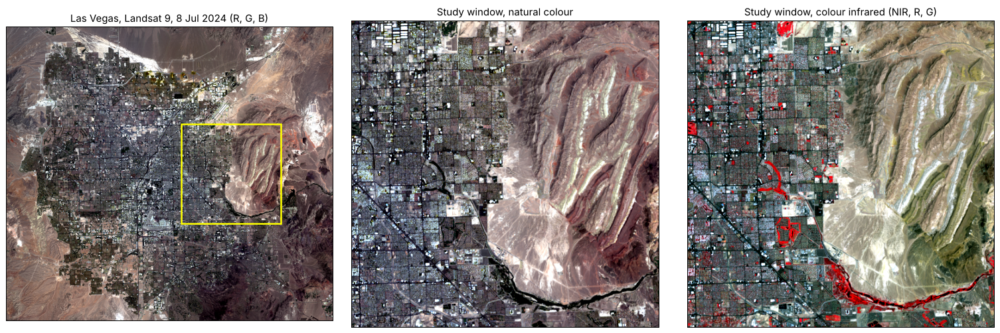

In [4]:
# Where the study window lies, and how it looks in natural colour and colour infrared.
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))  # three panels side by side
# full scene, red-green-blue
rs.viz.plot_rgb(ls, "true_color", ax=axes[0], title="Las Vegas, Landsat 9, 8 Jul 2024 (R, G, B)")
# the study window in yellow (x = column 900, y = row 500)
axes[0].add_patch(Rectangle((900, 500), 512, 512, fill=False, ec="yellow", lw=2))
# the window in natural colour
rs.viz.plot_rgb(sub, "true_color", ax=axes[1], title="Study window, natural colour")
# NIR, red, green: vegetation appears red
rs.viz.plot_rgb(sub, "false_color", ax=axes[2], title="Study window, colour infrared (NIR, R, G)")
for a in axes:  # hide the pixel ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

In [5]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

# Colour-infrared input (NIR, red, green) as one DataArray with a leading "band" dimension.
# NIR, red and green stacked as three channels (like an RGB photo)
cir = sub[["nir", "red", "green"]].to_array("band")
print(cir.dims, cir.shape)  # dimensions and shape: (band, y, x)

('band', 'y', 'x') (3, 512, 512)


## Inside the network: first-layer filters

The 64 kernels of ResNet-18's first convolution (7 × 7 × 3) are shown as small RGB images. Most are
oriented edge detectors and colour-opponent blobs, a learned counterpart of the Gabor bank in notebook
09_07_02.


conv1 weights: (64, 3, 7, 7)


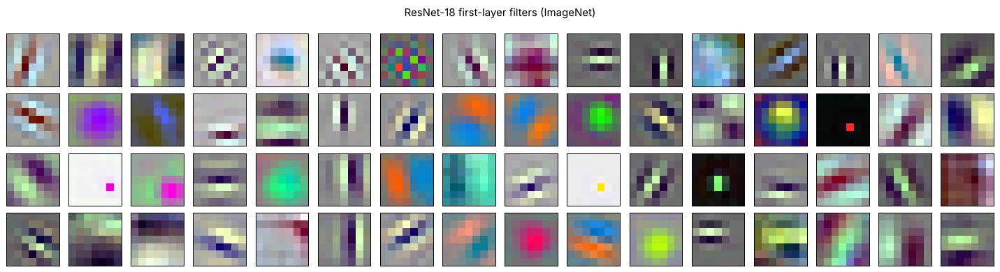

In [6]:
# ResNet-18 with ImageNet weights (downloaded once by timm)
backbone = timm.create_model("resnet18", pretrained=True)
# first convolution: 64 filters of 3 x 7 x 7
w = backbone.conv1.weight.detach().numpy()            # (64, 3, 7, 7)
print("conv1 weights:", w.shape)  # weight shape
fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))  # one panel per filter
for k, ax in enumerate(axes.ravel()):  # loop over the 64 filters
    f = w[k].transpose(1, 2, 0)  # (3, 7, 7) -> (7, 7, 3) for imshow
    f = (f - f.min()) / (f.max() - f.min())  # scale to 0-1 so it can be shown as colour
    ax.imshow(f, interpolation="nearest"); ax.set_xticks([]); ax.set_yticks([])  # show the filter, no ticks
plt.suptitle("ResNet-18 first-layer filters (ImageNet)")  # overall title
plt.tight_layout(); plt.show()  # arrange and draw

Many filters are oriented edge and bar detectors at different angles and widths, a learned version of
the Gabor bank. Others are colour-opponent blobs (green against magenta, blue against orange) and a few
are centre-surround or single-pixel detectors.


## Feature maps of the ResNet-18 stages

`tx.deep_texture_features(cir, layer=k)` returns a Dataset with one variable per channel (`deep_0`,
`deep_1`, ...). With 64 to 256 channels, looking at maps one by one is impractical, so we project each
pixel's feature vector onto its first three **principal components** and show them as an RGB image:
pixels with similar colours have similar deep features.


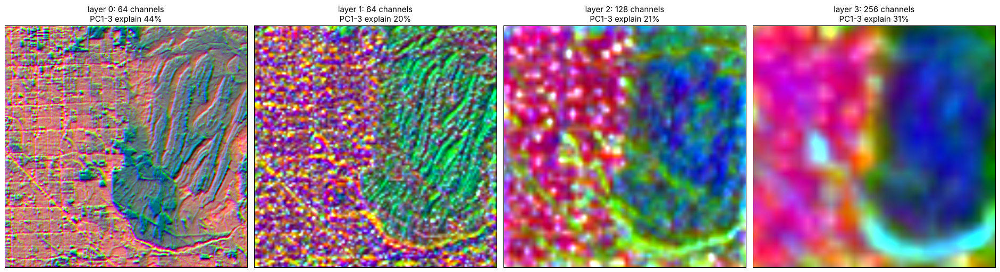

,layer,channels,seconds,PC1-3 variance
0,0,64,2.1,44%
1,1,64,2.8,20%
2,2,128,3.9,21%
3,3,256,7.4,31%


In [7]:
def to_matrix(ds):  # Dataset of feature maps -> (pixels, channels) array
    """(pixels, channels) matrix of a deep-feature Dataset, in row-major (y, x) order."""
    return np.stack([ds[v].values.ravel() for v in ds.data_vars], axis=1)  # one column per channel

def pca_rgb(ds, n=3):  # show many channels as one colour image
    X = to_matrix(ds)  # pixels x channels
    ok = np.isfinite(X).all(axis=1)  # pixels without missing values
    pcs = np.full((X.shape[0], n), np.nan)  # first n principal components per pixel
    pca = PCA(n).fit(X[ok][::7])  # fit on every seventh valid pixel (faster)
    pcs[ok] = pca.transform(X[ok])  # project all valid pixels
    lo, hi = np.nanpercentile(pcs, [2, 98], axis=0)  # 2-98 % stretch per component
    # PC1-3 as red, green, blue
    rgb = np.clip((pcs - lo) / (hi - lo), 0, 1).reshape(ds.sizes["y"], ds.sizes["x"], n)
    return rgb, pca.explained_variance_ratio_  # image and explained variance

deep = {}  # feature Dataset per ResNet stage
rows = []  # summary rows
fig, axes = plt.subplots(1, 4, figsize=(21, 5.5))  # four panels
for ax, layer in zip(axes, [0, 1, 2, 3]):  # ResNet-18 stages 0-3
    t0 = time.time()  # time each stage
    # feature maps of this stage, resampled to the image grid
    deep[layer] = tx.deep_texture_features(cir, model_name="resnet18", layer=layer)
    secs = time.time() - t0  # run time
    rgb, evr = pca_rgb(deep[layer])  # colour composite of PC1-3
    ax.imshow(rgb); ax.set_xticks([]); ax.set_yticks([])  # show it, no ticks
    # channels and explained variance
    ax.set_title(f"layer {layer}: {len(deep[layer].data_vars)} channels\nPC1-3 explain {evr.sum():.0%}")
    # summary row
    rows.append({"layer": layer, "channels": len(deep[layer].data_vars), "seconds": round(secs, 1),
                 "PC1-3 variance": f"{evr.sum():.0%}"})  # as a percentage
plt.tight_layout(); plt.show()  # arrange and draw
# show the table
pd.DataFrame(rows)

- **Layer 0** (stride 2) looks like shaded relief: the stem filters respond to oriented gradients, so
  every ridge appears lit from one side. Three components explain 44% of the variance.
- **Layer 1** (stride 4) turns the city into a dense mosaic, the ridges into green streaks and outlines the
  Wash. Three components explain only 20%: the 64 channels carry many independent signals.
- **Layer 2** (stride 8) separates city, mountain and Wash as regions with sharp-ish boundaries.
- **Layer 3** (stride 16, receptive field about 6 km) keeps only broad regions.

On a CPU each pass over the 512 × 512 window takes 2 to 7 seconds.


### Individual channels of layer 1

The eight layer-1 channels with the highest spatial variance.


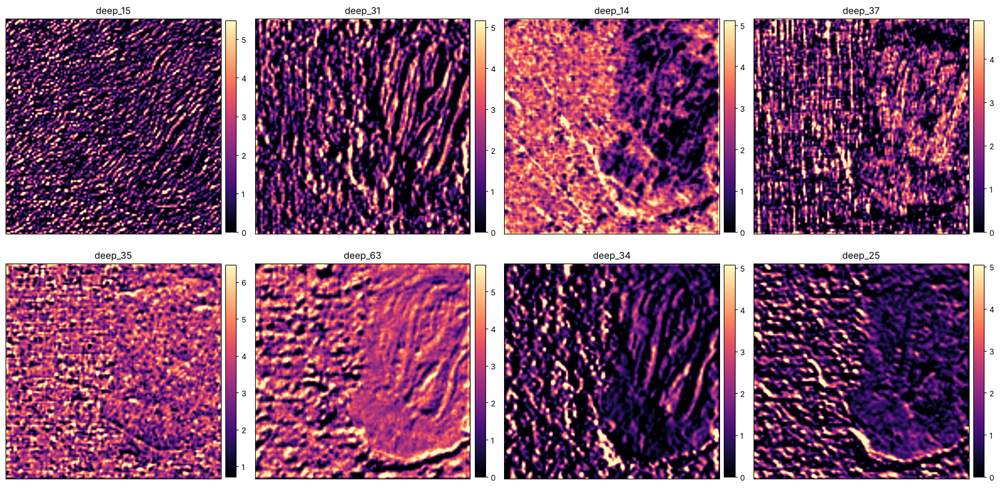

Cumulative variance of the first 10 PCs of layer 1: [0.08  0.142 0.199 0.252 0.305 0.353 0.397 0.438 0.476 0.51 ]


In [8]:
d1 = deep[1]  # stage-1 features
var = {k: float(d1[k].var()) for k in d1.data_vars}  # variance of each channel
top = sorted(var, key=var.get, reverse=True)[:8]  # the eight most variable channels
fig, axes = plt.subplots(2, 4, figsize=(18, 9))  # 2 x 4 panels
for ax, k in zip(axes.ravel(), top):  # one panel per channel
    rs.viz.plot_raster(d1[k], ax=ax, cmap="magma", title=k)  # draw it
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw

# How many principal components are needed for layer 1?
X1 = to_matrix(d1)  # stage-1 features as pixels x channels
pca1 = PCA(20).fit(X1[np.isfinite(X1).all(axis=1)][::7])  # 20 components fitted on every seventh valid pixel
cum = np.cumsum(pca1.explained_variance_ratio_)  # cumulative explained variance
# how many components hold most of the information
print("Cumulative variance of the first 10 PCs of layer 1:", np.round(cum[:10], 3))

The first 10 principal components of layer 1 explain only 51% of the variance. Deep features are high-
dimensional, and a compact stack needs at least 8 to 10 components.


## Choosing the input bands

The network sees only three channels, so the band choice matters. We compare the colour-infrared
composite, true colour, and the NIR band repeated three times (what the function does with a single
band).


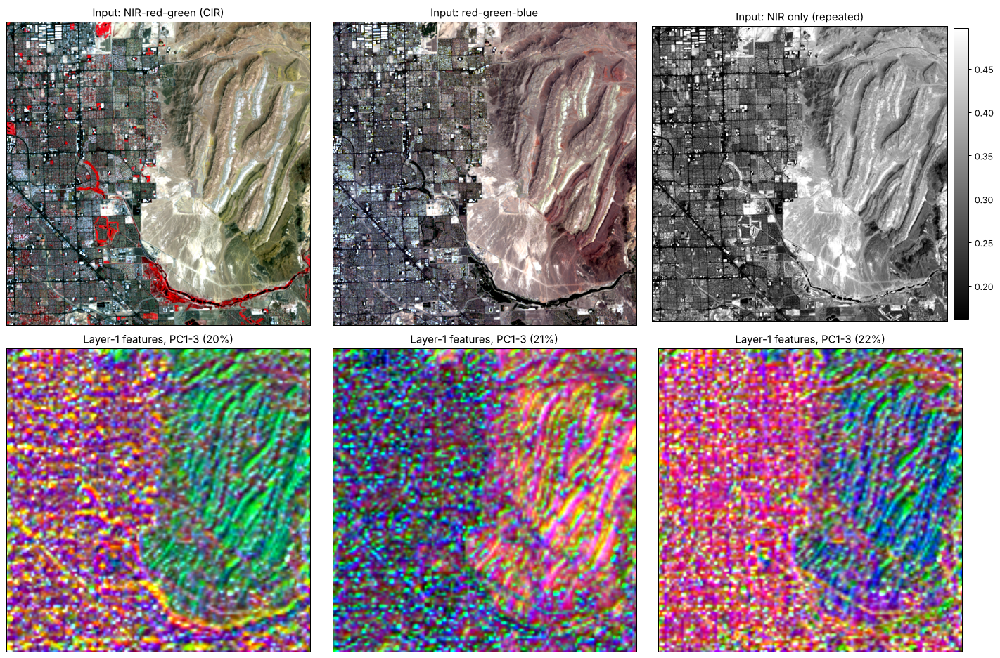

In [9]:
inputs = {"NIR-red-green (CIR)": cir,  # three ways to feed the 3-channel network
          "red-green-blue": sub[["red", "green", "blue"]].to_array("band"),  # true colour
          "NIR only (repeated)": nir}  # one band; GeoLattice repeats it to three channels
feats_in = {}  # stage-1 features per input
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))  # inputs (top), features (bottom)
for j, (name, arr) in enumerate(inputs.items()):  # one column per input
    feats_in[name] = tx.deep_texture_features(arr, layer=1)  # stage-1 features
    if "band" in arr.dims:  # multi-band inputs: show as colour
        # false or true colour
        rs.viz.plot_rgb(sub, "false_color" if "NIR-red" in name else "true_color", ax=axes[0, j], title=f"Input: {name}")
    else:  # single band: grey image
        rs.viz.plot_raster(arr, ax=axes[0, j], cmap="gray", title=f"Input: {name}")  # the NIR band
    rgb, evr = pca_rgb(feats_in[name])  # colour composite of the features
    axes[1, j].imshow(rgb); axes[1, j].set_title(f"Layer-1 features, PC1-3 ({evr.sum():.0%})")  # show it
for a in axes.ravel():  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

In [10]:
# Agreement between inputs: correlation of the first principal component of each feature set.
pc1 = {}  # first principal component per input
for name, ds in feats_in.items():  # loop over the inputs
    X = to_matrix(ds); ok = np.isfinite(X).all(axis=1)  # pixels x channels; valid rows
    # PC1 of the valid pixels, NaN elsewhere
    p = np.full(X.shape[0], np.nan); p[ok] = PCA(1).fit_transform(X[ok])[:, 0]
    pc1[name] = p  # store it
# absolute correlation (the sign of a PC is arbitrary)
pd.DataFrame(pc1).corr().abs().round(2)

,NIR-red-green (CIR),red-green-blue,NIR only (repeated)
NIR-red-green (CIR),1.00,0.87,0.85
red-green-blue,0.87,1.00,0.89
NIR only (repeated),0.85,0.89,1.00


The first principal components of the three inputs agree closely (|r| = 0.85 to 0.89): the dominant
texture pattern does not depend much on the bands. The details do: the CIR input outlines the vegetated
Wash and parks, which are dull in true colour.


## Pooled tile descriptors: search and clustering

With `reduce="mean"`, the function averages every channel over the whole input and returns one number
per channel: a compact **descriptor** of the texture of an image tile. We cut the study window into
256 tiles of 32 × 32 pixels (960 m) and describe each with the 64 layer-1 means.


In [11]:
T = 32  # tile size in pixels (960 m)
n_t = 512 // T  # 16 tiles per side
t0 = time.time()  # start the timer
desc, centers = [], []  # descriptor and (row, col) of every tile
for i in range(n_t):  # tile rows
    for j in range(n_t):  # tile columns
        tile = cir.isel(y=slice(i * T, (i + 1) * T), x=slice(j * T, (j + 1) * T))  # the CIR pixels of this tile
        # stage-1 features averaged over the tile (one vector)
        d = tx.deep_texture_features(tile, layer=1, reduce="mean")
        desc.append([d[f"deep_{k}_mean"] for k in range(len(d))])  # the vector as a list
        centers.append((i, j))  # tile position
D = np.array(desc)  # tiles x features
print(f"{len(D)} tiles x {D.shape[1]} features in {time.time() - t0:.0f} s")  # size and run time

256 tiles x 64 features in 105 s


Running the backbone on 256 separate tiles takes about 100 seconds on a CPU, because the model is built
for every call. For many tiles it is much faster to run `tx.deep_texture_features` once on the whole
window and average the feature maps per tile, for example with
`deep[1].coarsen(y=32, x=32).mean()`; the result differs slightly at tile edges, where a single pass sees
the neighbouring tiles.


### Similarity search

Choose a query tile and rank all tiles by the **cosine similarity** of their standardized descriptors.
This is content-based image retrieval: "find the places that look like this one".


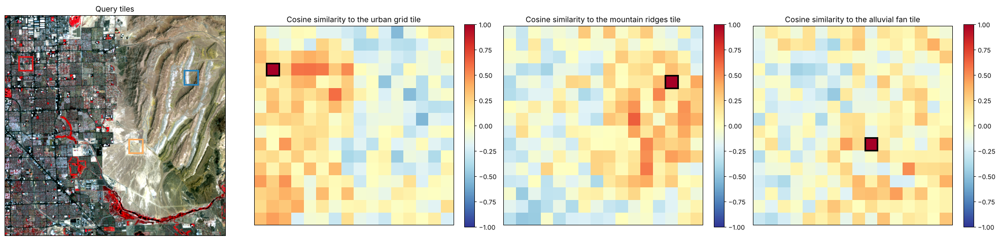

In [12]:
from sklearn.preprocessing import StandardScaler  # standardisation
Dz = StandardScaler().fit_transform(D)  # each feature to mean 0, std 1
Dn = Dz / np.linalg.norm(Dz, axis=1, keepdims=True)  # unit-length rows, so a dot product is a cosine similarity

# one query tile per landscape
queries = {"Urban grid": (3, 1), "Mountain ridges": (4, 13), "Alluvial fan": (9, 9)}   # (tile row, tile col)
fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))  # query map and three similarity maps
rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Query tiles")  # background for the query tiles
for ax, (name, (qi, qj)) in zip(axes[1:], queries.items()):  # loop over the queries
    q = qi * n_t + qj  # row index of the query tile in D
    sim = (Dn @ Dn[q]).reshape(n_t, n_t)  # cosine similarity of every tile to the query, as a 16 x 16 grid
    # drawn over the 512-pixel window
    im = ax.imshow(sim, cmap="RdYlBu_r", vmin=-1, vmax=1, extent=(0, 512, 512, 0))
    ax.add_patch(Rectangle((qj * T, qi * T), T, T, fill=False, ec="k", lw=2.5))  # the query tile in black
    # and in its colour on the overview
    axes[0].add_patch(Rectangle((qj * T, qi * T), T, T, fill=False, ec=COLORS[name], lw=2.5))
    ax.set_title(f"Cosine similarity to the {name.lower()} tile")  # title
    plt.colorbar(im, ax=ax, fraction=0.046)  # colour bar
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

The urban query tile is similar (0.25 to 0.6) to almost every other city tile and dissimilar to the
mountain and fan. The ridge query finds other ridge tiles across Frenchman Mountain. The fan query gives
weak, scattered similarities: the fan has little texture, so its descriptor is close to the average of
all tiles.


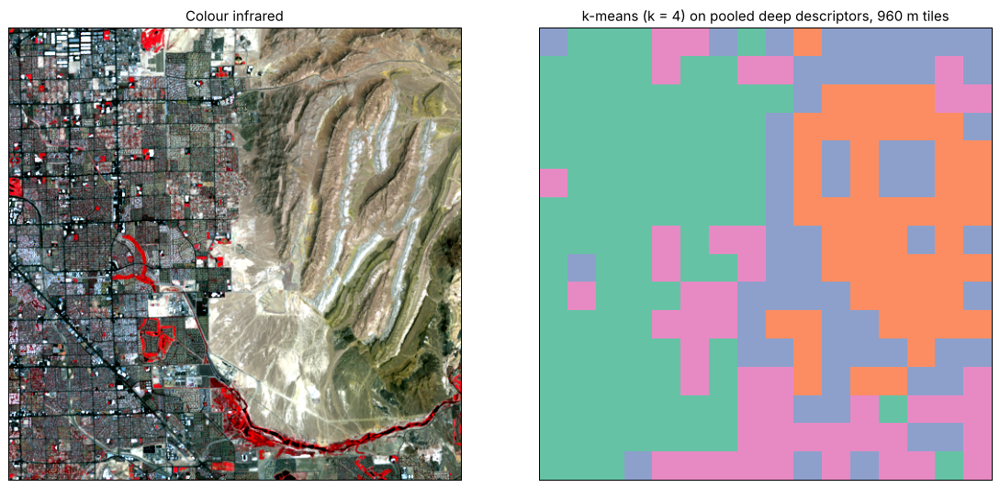

In [13]:
from sklearn.cluster import KMeans  # k-means
from matplotlib.colors import ListedColormap  # a fixed four-colour map
km_t = KMeans(4, n_init=10, random_state=0).fit(Dz)  # four clusters of tile descriptors
tile_map = km_t.labels_.reshape(n_t, n_t)  # labels back on the 16 x 16 tile grid

fig, axes = plt.subplots(1, 2, figsize=(13, 6))  # two panels
rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Colour infrared")  # reference image
# tile clusters drawn over the 512-pixel window
axes[1].imshow(tile_map, cmap=ListedColormap(["#66c2a5", "#fc8d62", "#8da0cb", "#e78ac3"]),
               extent=(0, 512, 512, 0), interpolation="nearest")  # nearest: keep the tiles square
axes[1].set_title("k-means (k = 4) on pooled deep descriptors, 960 m tiles")  # title
for a in axes:  # no ticks
    a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()  # arrange and draw

Four clusters of pooled descriptors map the main units of the window at 960 m: the city (green), the
mountain core (orange), the fan and mountain margins (blue), and the Wash and the southern edge of the
city (pink). For tile-level tasks such as scene classification or retrieval, pooled deep descriptors work
well without any tuning.


## Deep features and hand-crafted texture

How do the deep features relate to the classic measures of notebooks 09_07_01 to 09_07_04? We correlate
the first five principal components of the layer-1 features with a few hand-crafted measures computed
on NIR.


hand-crafted features: 21.5 s


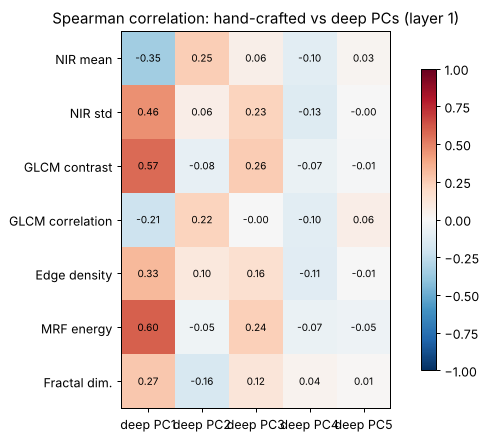

In [14]:
t0 = time.time()  # start the timer
hand = xr.Dataset({  # hand-crafted texture layers from the earlier notebooks
    "NIR mean": tx.first_order_stats(nir, size=9, stats=("mean",))["mean"],  # first-order mean
    "NIR std": tx.first_order_stats(nir, size=9, stats=("std",))["std"],  # first-order standard deviation
    "GLCM contrast": tx.glcm_texture(nir, size=9, step=2, props=("contrast",))["contrast"],  # GLCM contrast
    # GLCM correlation
    "GLCM correlation": tx.glcm_texture(nir, size=9, step=2, props=("correlation",))["correlation"],
    "Edge density": tx.edge_density(nir, size=9),  # structural
    "MRF energy": tx.mrf_texture_energy(nir, size=9),  # model-based
    "Fractal dim.": tx.fractal_dimension(nir, size=32, step=4),  # model-based
})
print(f"hand-crafted features: {time.time() - t0:.1f} s")  # run time

ok = np.isfinite(X1).all(axis=1)  # valid pixels of the stage-1 features
pcs = np.full((X1.shape[0], 5), np.nan)  # first five deep principal components
pcs[ok] = PCA(5).fit(X1[ok][::7]).transform(X1[ok])  # fit on every seventh pixel, project all
hdf = pd.DataFrame({v: hand[v].values.ravel() for v in hand.data_vars})  # hand-crafted features as columns
for k in range(5):  # add the deep PCs as columns
    hdf[f"deep PC{k + 1}"] = pcs[:, k]  # one column per PC
# rank correlation: hand-crafted (rows) vs deep PCs (columns)
cc = hdf.corr(method="spearman").loc[list(hand.data_vars), [f"deep PC{k + 1}" for k in range(5)]]

fig, ax = plt.subplots(figsize=(7, 5))  # one panel
im = ax.imshow(cc, cmap="RdBu_r", vmin=-1, vmax=1)  # the correlation matrix
ax.set_xticks(range(5), cc.columns); ax.set_yticks(range(len(cc)), cc.index)  # labels
for i in range(cc.shape[0]):  # write each value in its cell
    for j in range(cc.shape[1]):  # columns
        ax.text(j, i, f"{cc.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)  # two decimals
# colour bar and title
plt.colorbar(im, shrink=0.8); ax.set_title("Spearman correlation: hand-crafted vs deep PCs (layer 1)")
plt.tight_layout(); plt.show()  # arrange and draw

The first deep component is a **roughness axis**: it correlates with MRF energy (0.60), GLCM contrast
(0.57), local std (0.46) and edge density (0.33). The second relates weakly to brightness and GLCM
correlation. Components 3 to 5 have little counterpart among the hand-crafted measures: deep features
reproduce the main roughness signal of classic texture and add other, less interpretable information.


## Application: texture signatures and clustering


Three 40 × 40 pixel boxes (1.2 × 1.2 km), chosen by eye on the false-colour image, are used to compare
texture signatures:

| Box | Rows | Columns | Surface |
|---|---|---|---|
| Urban grid | 100-140 | 40-80 | Residential blocks and streets |
| Alluvial fan | 300-340 | 270-310 | Smooth bare desert soil |
| Mountain ridges | 130-170 | 400-440 | Folded sedimentary ridges of Frenchman Mountain |


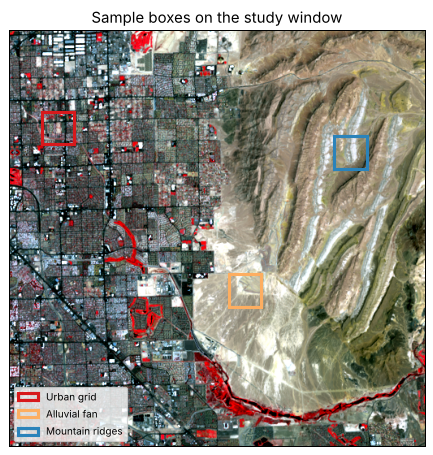

In [15]:
# three 40 x 40 pixel sample boxes (rows, columns) in the study window
BOXES = {"Urban grid": (slice(100, 140), slice(40, 80)),
         "Alluvial fan": (slice(300, 340), slice(270, 310)),  # gravel slopes east of the city
         "Mountain ridges": (slice(130, 170), slice(400, 440))}  # rugged terrain
# one colour per box
COLORS = {"Urban grid": "#d7191c", "Alluvial fan": "#fdae61", "Mountain ridges": "#2b83ba"}

fig, ax = plt.subplots(figsize=(6, 6))  # one panel
# colour infrared background
rs.viz.plot_rgb(sub, "false_color", ax=ax, title="Sample boxes on the study window")
for name, (ys, xs) in BOXES.items():  # draw each box
    # x = column start, y = row start, then width and height
    ax.add_patch(Rectangle((xs.start, ys.start), xs.stop - xs.start, ys.stop - ys.start,
                           # outline only, labelled for the legend
                           fill=False, ec=COLORS[name], lw=2.5, label=name))
ax.legend(loc="lower left", fontsize=8); ax.set_xticks([]); ax.set_yticks([])  # legend, no ticks
plt.show()  # draw

In [16]:
from sklearn.cluster import KMeans  # k-means clustering
from sklearn.preprocessing import StandardScaler  # standardise features to mean 0, std 1
from scipy.ndimage import generic_filter  # moving-window filter for the speckle measure

def box_means(ds):  # average feature values per sample box
    """Mean of every variable of `ds` inside each sample box."""
    # rows = features, columns = boxes
    return pd.DataFrame({name: {v: float(ds[v].isel(y=ys, x=xs).mean()) for v in ds.data_vars}
                         for name, (ys, xs) in BOXES.items()})

def plot_signatures(sig, title):  # compare the boxes feature by feature
    """Bar chart of box means, min-max scaled per feature across the three boxes."""
    # scale each feature to 0-1 across the three boxes
    norm = sig.sub(sig.min(axis=1), axis=0).div(sig.max(axis=1) - sig.min(axis=1), axis=0)
    fig, ax = plt.subplots(figsize=(max(7, 0.75 * len(norm)), 4.5))  # width grows with the number of features
    x = np.arange(len(norm))  # one group of bars per feature
    for k, name in enumerate(norm.columns):  # one bar per box, shifted sideways
        ax.bar(x + (k - 1) * 0.27, norm[name], width=0.27, color=COLORS[name], label=name)  # draw the bars
    ax.set_xticks(x, norm.index, rotation=45, ha="right")  # feature names, rotated
    ax.set(ylabel="Relative value (0 = lowest box, 1 = highest)", title=title)  # labels
    ax.legend(); plt.tight_layout(); plt.show()  # legend and draw

def kmeans_map(ds, k=5, n_fit=40000, seed=0):  # unsupervised map from a set of layers
    """Standardize the layers, fit k-means on a random pixel sample and label every pixel."""
    df = ds.to_dataframe(dim_order=["y", "x"])[list(ds.data_vars)]  # pixels as rows, layers as columns
    ok = df.notna().all(axis=1).values  # pixels without missing values
    X = StandardScaler().fit_transform(df[ok].values)  # standardise so every layer weighs the same
    rng = np.random.default_rng(seed)  # random sample generator
    # fit on at most 40,000 random pixels (faster)
    km = KMeans(k, n_init=10, random_state=seed).fit(X[rng.choice(len(X), min(n_fit, len(X)), replace=False)])
    lab = np.full(ok.size, np.nan); lab[ok] = km.predict(X)  # label all valid pixels; others stay NaN
    # labels back on the image grid
    return xr.DataArray(lab.reshape(ds.sizes["y"], ds.sizes["x"]), coords={"y": ds.y, "x": ds.x}, dims=("y", "x"))

def speckle(lab):  # how noisy a cluster map is
    """Share of pixels whose label differs from the majority label of their 3 x 3 neighbourhood."""
    a = np.nan_to_num(lab.values, nan=-1).astype(int)  # NaN -> -1 so the labels are integers
    # majority label in each 3 x 3 window
    mode = generic_filter(a, lambda v: np.bincount(v.astype(int) + 1).argmax() - 1, size=3)
    return float((a != mode).mean())  # share of pixels that differ from their neighbourhood majority

def box_purity(lab):  # how uniform each box is in a cluster map
    """Share of each box's pixels that fall in the box's most common cluster."""
    out = {}  # one value per box
    for name, (ys, xs) in BOXES.items():  # loop over the boxes
        v = lab.isel(y=ys, x=xs).values.ravel()  # labels inside the box
        v = v[np.isfinite(v)].astype(int)  # drop missing labels
        out[name] = np.bincount(v).max() / v.size  # share of the most common label
    return out  # dictionary box -> purity

# Spectral layers used as the baseline in every notebook: the four bands and NDVI.
# normalised difference vegetation index
ndvi = ((sub["nir"] - sub["red"]) / (sub["nir"] + sub["red"])).rename("NDVI")
spectral = xr.Dataset({**{b: sub[b] for b in BANDS}, "NDVI": ndvi})  # four bands plus NDVI

In [17]:
# The first 8 principal components of the layer-1 features as a compact deep-texture stack.
n_pc = 8  # number of components kept
pcs8 = np.full((X1.shape[0], n_pc), np.nan)  # PC scores per pixel
pcs8[ok] = PCA(n_pc).fit(X1[ok][::7]).transform(X1[ok])  # fit on every seventh pixel, project all
# each PC as a layer on the NIR grid
dl_feats = xr.Dataset({f"deep PC{k + 1}": nir.copy(data=pcs8[:, k].reshape(nir.shape)) for k in range(n_pc)})
sig = box_means(dl_feats)  # mean of each PC in each box
# show the table
sig.round(3)

,Urban grid,Alluvial fan,Mountain ridges
deep PC1,1.545,-1.336,-1.141
deep PC2,-0.681,0.224,-0.032
deep PC3,0.482,-0.649,-0.127
deep PC4,-0.168,0.133,-0.475
deep PC5,0.500,0.049,0.725
deep PC6,-0.003,0.913,0.552
deep PC7,0.045,0.376,-0.077
deep PC8,0.373,-0.710,-0.305


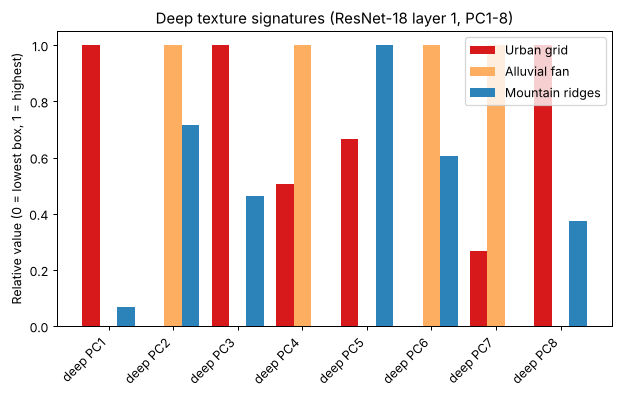

In [18]:
plot_signatures(sig, "Deep texture signatures (ResNet-18 layer 1, PC1-8)")  # bar chart of the box signatures

PC1 separates the city (+1.5) from the fan (−1.3) and the ridges (−1.1), confirming it as the roughness
axis. Later components separate the fan from the ridges (for example PC6 and PC8), which most
hand-crafted features could not.


### Does this family add information? A clustering test

Texture is useful only if it carries information that the spectral bands do not. We run k-means with
5 clusters on (a) the four bands and NDVI only and (b) the same spectral layers plus this notebook's
texture features, all standardized. Two numbers summarize the maps:

- **Speckle**: the share of pixels whose cluster differs from the majority of their 3 × 3
  neighbourhood (lower = more spatially coherent).
- **Purity**: the share of pixels in each sample box that fall in that box's most common cluster
  (higher = the surface is mapped as one unit).


In [19]:
def compare_clusterings(texture_ds, label):  # clustering with and without the texture layers
    """k-means on spectral layers only vs spectral + texture layers; maps, speckle and box purity."""
    k_spec = kmeans_map(spectral)  # five spectral layers
    k_both = kmeans_map(xr.merge([spectral, texture_ds], compat="override"))  # spectral plus texture layers
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))  # three panels
    rs.viz.plot_rgb(sub, "false_color", ax=axes[0], title="Colour infrared")  # reference image
    for ax, lab, t in zip(axes[1:], [k_spec, k_both],  # the two cluster maps with their titles
                          ["k-means, spectral only (5 layers)",
                           f"k-means, spectral + {label} ({5 + len(texture_ds.data_vars)} layers)"]):
        ax.imshow(lab, cmap="Set2", interpolation="nearest")  # one colour per cluster
        ax.set_title(f"{t}\nspeckle = {speckle(lab):.1%}")  # title with the speckle share
    for a in axes:  # no pixel ticks
        a.set_xticks([]); a.set_yticks([])
    plt.tight_layout(); plt.show()  # arrange and draw
    return pd.DataFrame({"spectral only": box_purity(k_spec),  # box purity of both maps, as percentages
                         # format each value as a percentage
                         f"spectral + {label}": box_purity(k_both)}).map(lambda v: f"{v:.0%}")

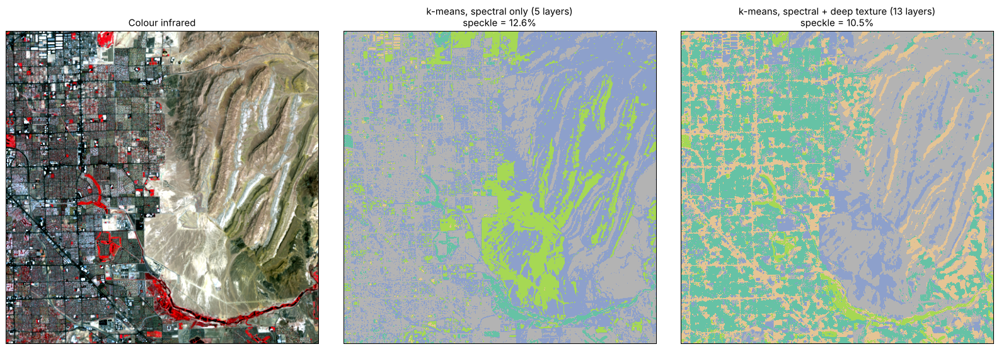

,spectral only,spectral + deep texture
Urban grid,53%,45%
Alluvial fan,58%,75%
Mountain ridges,66%,72%


In [20]:
compare_clusterings(dl_feats, "deep texture")  # maps, speckle and box purity

At pixel level, layer-1 features reduce speckle only a little (10.5%) and raise purity on the fan (75%)
and the ridges (72%), but the city is split into block-scale clusters (purity 45%). Unsupervised k-means
weights all 8 components equally, including components that describe city-block detail.


### Scale matters: layer 2 instead of layer 1

The same test with the first 8 principal components of **layer 2** (stride 8, receptive field about
3 km) instead of layer 1.


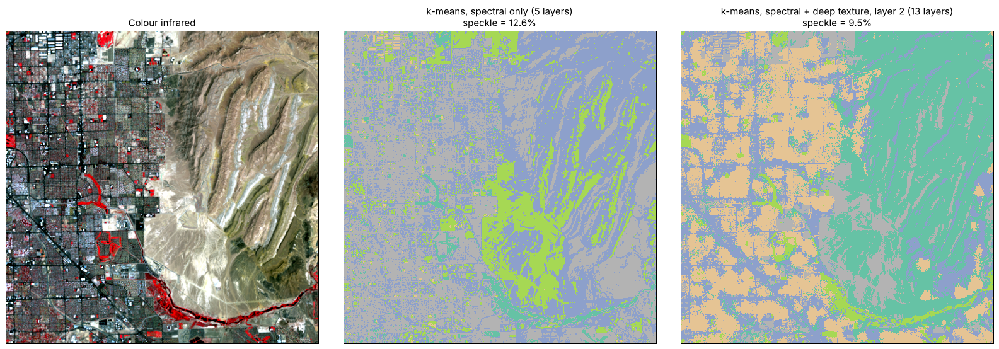

,spectral only,"spectral + deep texture, layer 2"
Urban grid,53%,47%
Alluvial fan,58%,67%
Mountain ridges,66%,79%


In [21]:
X2 = to_matrix(deep[2])  # stage-2 features as pixels x channels
ok2 = np.isfinite(X2).all(axis=1)  # valid pixels
pcs2 = np.full((X2.shape[0], n_pc), np.nan)  # eight PCs per pixel
pcs2[ok2] = PCA(n_pc).fit(X2[ok2][::7]).transform(X2[ok2])  # fit on every seventh pixel, project all
# PCs as layers on the NIR grid
dl2_feats = xr.Dataset({f"deep L2 PC{k + 1}": nir.copy(data=pcs2[:, k].reshape(nir.shape)) for k in range(n_pc)})
compare_clusterings(dl2_feats, "deep texture, layer 2")  # the same comparison with stage-2 features

Layer 2 (larger receptive field) gives slightly more coherent maps (speckle 9.5%) and the highest
ridge purity of the two (79%), while the city stays split (47%). For pixel-level mapping, deep features
need a supervised classifier that learns which components matter; for tile-level description they work
well as they are (see *Pooled tile descriptors*).


In [22]:
OUT = Path("outputs") / "texture"  # output folder for texture rasters
OUT.mkdir(parents=True, exist_ok=True)  # create it if needed
# Dataset -> one multi-band GeoTIFF (one band per feature)
dl_feats.to_array("feature").astype("float32").rio.write_crs(ls.rio.crs).rio.to_raster(OUT / "cir_deep_texture_pcs.tif")
with rasterio.open(OUT / "cir_deep_texture_pcs.tif") as src:  # read the file back to check it
    # number of bands, size and CRS
    print(f"cir_deep_texture_pcs.tif: {src.count} bands, {src.width} x {src.height}, {src.crs}")

cir_deep_texture_pcs.tif: 8 bands, 512 x 512, EPSG:32611


## Summary and exercises

**Key points**

- CNN feature maps are the responses of learned filter banks. Early layers respond to edges, colour
  contrasts and simple textures and transfer well from ImageNet to satellite images.
- `tx.deep_texture_features` turns any three bands into tens to hundreds of texture layers, with no
  texture parameters to tune; the choice of `layer` sets the spatial scale.
- PCA makes the many channels interpretable and gives a compact stack for classification.
- Pooled (`reduce="mean"`) descriptors describe whole tiles and support similarity search and tile
  clustering.
- The first deep component is a roughness axis that correlates moderately (up to 0.6) with MRF energy and
  GLCM contrast; the other components add information that hand-crafted measures do not capture.
- At 30 m, the large receptive fields of deeper stages blur boundaries. Layers 1 and 2 balance detail
  and context for pixel-level Landsat work, and pixel-level use needs a supervised classifier; pooled
  tile descriptors work well without one.

**`geolattice.rsense` functions used:** `rs.read`, `rs.optical.scale`, `rs.viz.plot_rgb`, `rs.viz.plot_raster`,
`tx.deep_texture_features`, and, for comparison, `tx.first_order_stats`, `tx.glcm_texture`,
`tx.edge_density`, `tx.mrf_texture_energy`, `tx.fractal_dimension`.

**Exercises**

1. Repeat the ResNet-18 feature maps with `model_name="resnet50"` or `"efficientnet_b0"`. Are the layer-1 features
   different?
2. Compute the Gram matrix of the layer-1 feature maps for each 32 × 32 tile and use its upper
   triangle as a descriptor. Does tile clustering improve?
3. Build the tile descriptors from SWIR1-NIR-red instead of NIR-red-green.
4. Pansharpen the scene to 15 m (Landsat band 8) and compare the layer-1 features with the 30 m result.
5. Label 50 tiles by hand (urban, desert, mountain, water/vegetation) and train a logistic regression on
   the pooled descriptors. How many labels do you need for 90% accuracy?

**References**

- Cimpoi, M., Maji, S. and Vedaldi, A. (2015). Deep filter banks for texture recognition and
  segmentation. *CVPR*, 3828-3836.
- Gatys, L.A., Ecker, A.S. and Bethge, M. (2015). Texture synthesis using convolutional neural networks.
  *NeurIPS*, 262-270.
- He, K., Zhang, X., Ren, S. and Sun, J. (2016). Deep residual learning for image recognition. *CVPR*,
  770-778.
- Hu, F., Xia, G.-S., Hu, J. and Zhang, L. (2015). Transferring deep convolutional neural networks for
  the scene classification of high-resolution remote sensing imagery. *Remote Sensing*, 7(11),
  14680-14707.
- Penatti, O.A.B., Nogueira, K. and dos Santos, J.A. (2015). Do deep features generalize from everyday
  objects to remote sensing and aerial scenes domains? *CVPR Workshops*, 44-51.
- Zeiler, M.D. and Fergus, R. (2014). Visualizing and understanding convolutional networks. *ECCV*,
  818-833.

**Previous:** [Model-based texture](09_07_04_texture_analysis_of_landsat_imagery_model_based_methods.ipynb) ·
**Series start:** [Statistical and structural texture](09_07_01_texture_analysis_of_landsat_imagery_statistical_and_structural_methods.ipynb).
